In [14]:
import sys
sys.path.append("..")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src.curves.data import charger_courbe, charger_parametres
from src.curves.svensson import sv_rate, fit_sv

In [15]:
#on récupère les données
courbe = charger_courbe("../data/raw/yield_curve.csv")
param = charger_parametres("../data/raw/param.csv")
T = courbe.columns.values

print(courbe.shape, param.shape, (courbe.index == param.index).all())

(5662, 197) (5662, 6) True


In [16]:
#contrôle de la formule avec les paramètres de la BCE
date = "2026-10-28"
p_bce = param.loc[date].values        # [BETA0, BETA1, BETA2, BETA3, TAU1, TAU2]
ecart_pb = (courbe.loc[date].values - sv_rate(T, *p_bce)) * 1e4
print("écart max (pb) :", np.abs(ecart_pb).max().round(3),
      "| RMSE (pb) :", np.sqrt(np.mean(ecart_pb**2)).round(3))

écart max (pb) : 0.0 | RMSE (pb) : 0.0


In [17]:
#ajustement avec la veille comme point de départ
i = courbe.index.get_loc(pd.Timestamp(date))
veille = fit_sv(T, courbe.iloc[i - 1].values) #le 27 octobre
res = fit_sv(T, courbe.iloc[i].values, x_prev=veille.x)

print(res.success, "RMSE (pb) :", (np.sqrt(np.mean(res.fun**2)) * 1e4).round(4))
print(pd.DataFrame({"mon ajustement": res.x, "BCE": p_bce},
                   index=["beta0", "beta1", "beta2", "beta3", "tau1", "tau2"]).round(4))

True RMSE (pb) : 0.0
       mon ajustement      BCE
beta0          0.0164   0.0164
beta1          0.0069   0.0069
beta2          0.0232   0.0232
beta3          0.0632   0.0632
tau1           1.0530   1.0530
tau2          13.8103  13.8103


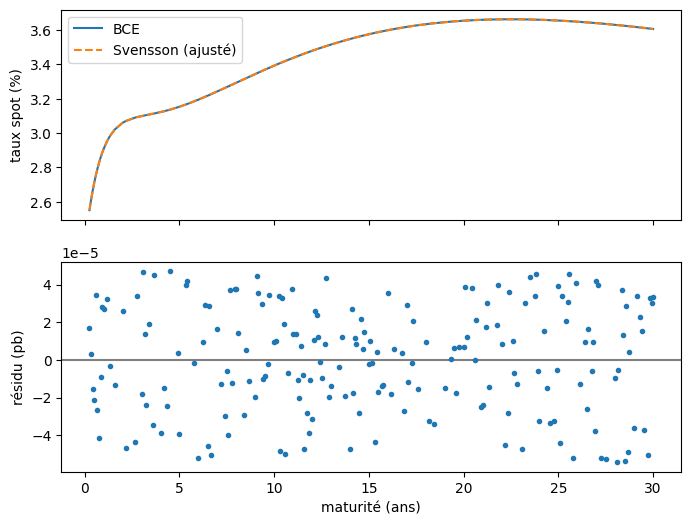

In [18]:
#graphique de la courbe et des résidus (convention observé − modèle)
y = courbe.iloc[i].values
fit = sv_rate(T, *res.x)

fig, ax = plt.subplots(2, 1, figsize=(8, 6), sharex=True)
ax[0].plot(T, y * 100, label="BCE")
ax[0].plot(T, fit * 100, "--", label="Svensson (ajusté)")
ax[0].set_ylabel("taux spot (%)")
ax[0].legend()
ax[1].axhline(0, color="gray")
ax[1].plot(T, (y - fit) * 1e4, ".")
ax[1].set_ylabel("résidu (pb)")
ax[1].set_xlabel("maturité (ans)")
plt.show()

In [19]:
# dix jours consécutifs, avec la veille transmise au lendemain
lignes, x_prev = [], None
for d in courbe.index[i - 9 : i + 1]:
    r = fit_sv(T, courbe.loc[d].values, x_prev=x_prev)
    x_prev = r.x
    lignes.append([d.date(), r.success, np.sqrt(np.mean(r.fun**2)) * 1e4, *r.x])

tab = pd.DataFrame(lignes, columns=["date", "succès", "rmse_pb",
                                    "b0", "b1", "b2", "b3", "tau1", "tau2"]).set_index("date")
tab.round(3)

,succès,rmse_pb,b0,b1,b2,b3,tau1,tau2
date,,,,,,,,
2026-10-15,True,0.0,0.017,0.007,0.019,0.063,0.994,14.208
2026-10-16,True,0.0,0.017,0.007,0.020,0.065,1.013,14.024
2026-10-19,True,0.0,0.017,0.007,0.020,0.065,1.035,14.015
2026-10-20,True,0.0,0.017,0.007,0.019,0.063,1.079,14.007
2026-10-21,True,0.0,0.017,0.007,0.019,0.063,1.075,14.001
2026-10-22,True,0.0,0.017,0.007,0.019,0.061,1.110,14.011
2026-10-23,True,0.0,0.017,0.007,0.018,0.061,1.105,14.146
2026-10-26,True,0.0,0.017,0.007,0.021,0.062,1.083,14.016
2026-10-27,True,0.0,0.017,0.007,0.022,0.063,1.011,13.769
